In [2]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit import generate_preset_pass_manager
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector
from qiskit.visualization import plot_circuit_layout, plot_gate_map,plot_coupling_map
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime.fake_provider import FakeBrisbane

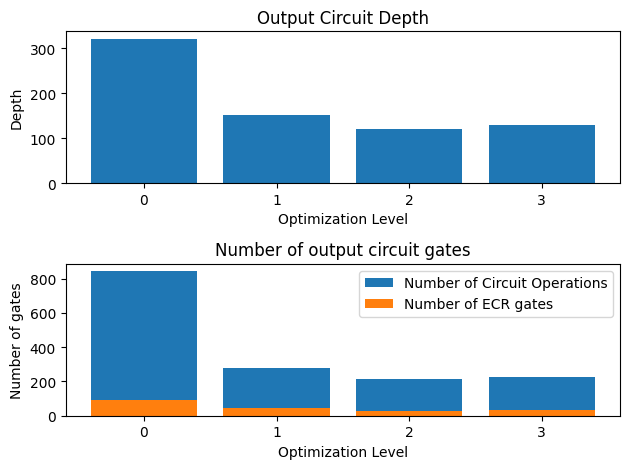

In [2]:
ghz = QuantumCircuit(15)
ghz.h(0)
ghz.cx(0, range(1, 15))
backend = FakeBrisbane()
depths = []
gate_counts = []
multiqubit_gate_counts = []
levels = [str(x) for x in range(4)]
for level in range(4):
    pass_manager = generate_preset_pass_manager(
        optimization_level=level,
        backend=backend,
        seed_transpiler=1234
    )
    circ = pass_manager.run(ghz)
    depths.append(circ.depth())
    gate_counts.append(sum(circ.count_ops().values()))
    multiqubit_gate_counts.append(circ.count_ops()["ecr"])

fig, (ax1, ax2) = plt.subplots(2, 1)
ax1.bar(levels, depths, label="Depth")
ax1.set_xlabel("Optimization Level")
ax1.set_ylabel("Depth")
ax1.set_title("Output Circuit Depth")
ax2.bar(levels, gate_counts, label="Number of Circuit Operations")
ax2.bar(levels, multiqubit_gate_counts, label="Number of ECR gates")
ax2.set_xlabel("Optimization Level")
ax2.set_ylabel("Number of gates")
ax2.legend()
ax2.set_title("Number of output circuit gates")
fig.tight_layout()
plt.show()

In [3]:
a=np.random.uniform(size=(10,1))
b=np.random.uniform(size=(1,10,1))
np.shape(a+b)

(1, 10, 1)

In [27]:
from qiskit.circuit.library import HGate
from qiskit.circuit.library import UnitaryGate
F = HGate()
B2 = UnitaryGate(np.exp(-np.pi*1j/8)/2*np.array([[1+1j,1-1j],[1-1j,1+1j]]))
Z12 = UnitaryGate(np.array([[1,0],[0,-1]]))
cZ12 = Z12.control(1)


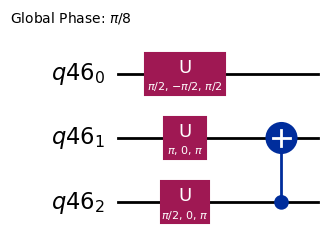

In [31]:
qreg = QuantumRegister(2)
circ = QuantumCircuit(qreg)
circ.h(0)
circ.cx(0,1)
qreg2 = QuantumRegister(3)
circ2 = QuantumCircuit(qreg2)
circ2.x(1)
circ3 = circ2.compose(circ,qubits=[2,1])
circ3.unitary(B2, [0], label='B2')
circ3 = circ3.decompose()
circ3.draw('mpl')


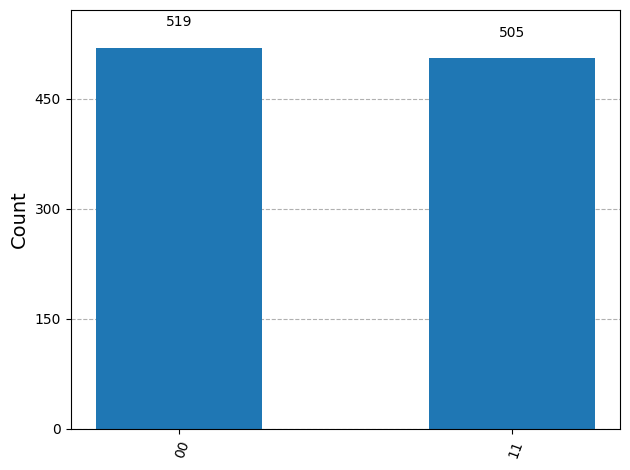

In [106]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram
qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)

state = Statevector.from_circuit(qc)
meas = state.sample_counts(shots=1024)
plot_histogram(meas)


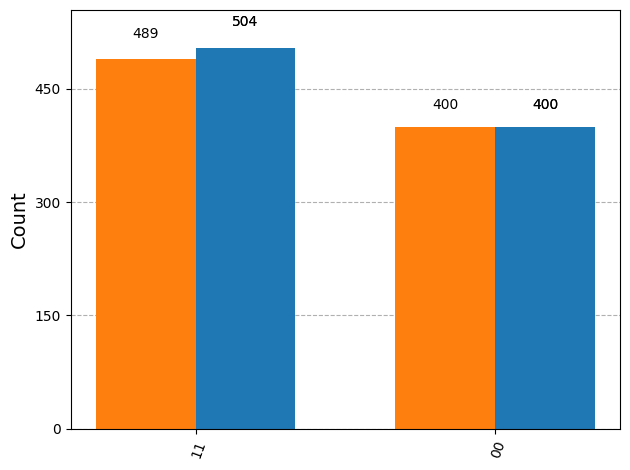

In [95]:
from qiskit.visualization import plot_histogram
 
counts1 = {'00': 400, '11': 504}
counts2 = {'00': 400, '11': 489}
 
data = [counts1, counts2]
plot_histogram(data, sort='value_desc')

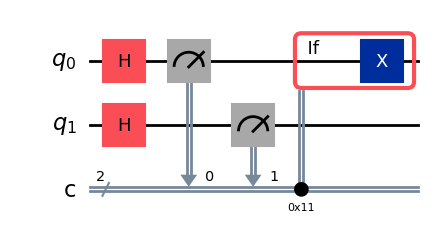

In [28]:
from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister
n = 2
qreg = QuantumRegister(n, name='q')
creg = ClassicalRegister(n, name='c')
qc = QuantumCircuit(qreg, creg)
qc.h(qreg)

qc.measure(qreg, creg)
with qc.if_test((creg,0b10001)):
    qc.x(0)
    
qc.draw('mpl')

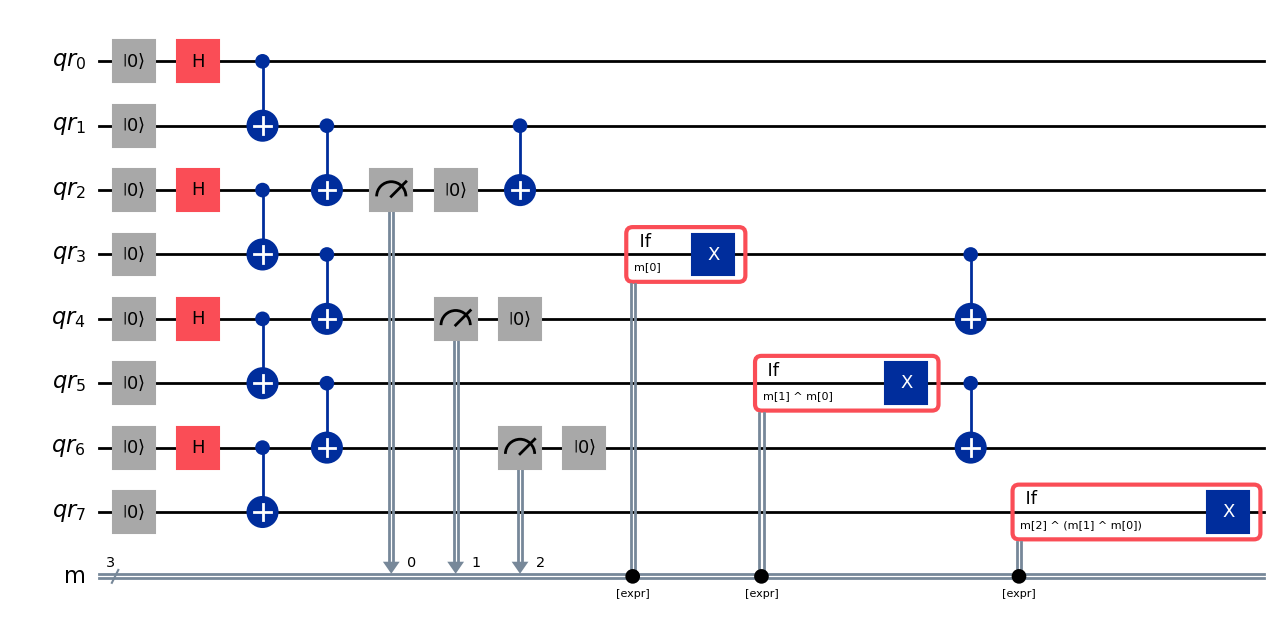

In [30]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit.classical import expr

num_qubits = 8
if num_qubits % 2 or num_qubits < 4:
    raise ValueError("num_qubits must be an even integer ≥ 4")
meas_qubits = list(range(2, num_qubits, 2))  # qubits to measure and reset

qr = QuantumRegister(num_qubits, "qr")
mr = ClassicalRegister(len(meas_qubits), "m")
qc = QuantumCircuit(qr, mr)

# Create local Bell pairs
qc.reset(qr)
qc.h(qr[::2])
for ctrl in range(0, num_qubits, 2):
    qc.cx(qr[ctrl], qr[ctrl + 1])

# Glue neighboring pairs
for ctrl in range(1, num_qubits - 1, 2):
    qc.cx(qr[ctrl], qr[ctrl + 1])

# Measure boundary qubits between pairs,reset to 0
for k, q in enumerate(meas_qubits):
    qc.measure(qr[q], mr[k])
    qc.reset(qr[q])

# Parity-conditioned X corrections
# Each non-measured qubit gets flipped iff the parity (XOR) of all
# preceding measurement bits is 1
for tgt in range(num_qubits):
    if tgt in meas_qubits:  # skip measured qubits
        continue
    # all measurement registers whose physical qubit index < tgt
    left_bits = [k for k, q in enumerate(meas_qubits) if q < tgt]
    if not left_bits:  # skip if list empty
        continue

    # build XOR-parity expression
    parity = expr.lift(
        mr[left_bits[0]]
    )  # lift the first bit to Value so it will be treated like a boolean.
    for k in left_bits[1:]:
        parity = expr.bit_xor(
            mr[k], parity
        )  # calculate parity with all other bits
    with qc.if_test(parity):  # Add X if parity is 1
        qc.x(qr[tgt])

# Re-entangle measured qubits
for ctrl in range(1, num_qubits - 1, 2):
    qc.cx(qr[ctrl], qr[ctrl + 1])
qc.draw(output="mpl", style="iqp", idle_wires=False, fold=-1)

native gates:['cx', 'delay', 'id', 'measure', 'reset', 'rz', 'sx', 'x']


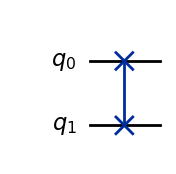

In [32]:
from qiskit.providers.fake_provider import GenericBackendV2

backend = GenericBackendV2(2)
print("native gates:" + str(sorted(backend.operation_names)))
qc = QuantumCircuit(2)
qc.swap(0, 1)
qc.draw("mpl")

In [35]:
class DatabaseConnection:
    def __enter__(self):
        print("Connecting to database...")
        self.conn = "DB_CONNECTION_OBJECT"  # Mock connection
        return self.conn  # This goes to the 'as' variable

    def __exit__(self, exc_type, exc_val, exc_tb):
        print("Closing database connection...")
        # Handle exceptions if needed
        if exc_type:
            print(f"An error occurred: {exc_val}")
        # Return False to re-raise exceptions; return True to suppress them
        return False 

# Usage:
with DatabaseConnection() as conn:
    print("Running query...")
    print(conn)
    # raise ValueError("Something went wrong!") # Uncomment to test exception handling
# Output: Closing database connection... (always runs)

Connecting to database...
Running query...
DB_CONNECTION_OBJECT
Closing database connection...


In [5]:
import numpy as np
a1 = np.zeros((3,1))
a2 = np.zeros((4,2))
a3 = a1 + a2
print(a3.shape)

ValueError: operands could not be broadcast together with shapes (3,1) (4,2) 

In [21]:
import numpy as np
from qiskit.circuit import Parameter, QuantumCircuit
from qiskit.primitives import StatevectorEstimator
from qiskit.quantum_info import SparsePauliOp

# 1. Define a simple quantum circuit with 2 parameters (a and b)
a = Parameter("a")
b = Parameter("b")
circuit = QuantumCircuit(2)
circuit.h(0)
circuit.cx(0, 1)
circuit.ry(a, 0)   # Parameter 'a'
circuit.rz(b, 0)   # Parameter 'b'
circuit.cx(0, 1)
circuit.h(0)

# 2. Define parameter values with shape (5, 2)
# This means 5 distinct sets of parameter values, each containing (a, b)
params = np.random.rand(100, 2)

# 3. Define observables with shape (3, 1)
# This is a list of 3 observables. Each observable is wrapped in a list of length 1.
observables = [
    [SparsePauliOp("XX")],                       # Observable 1: Pauli XX
    [SparsePauliOp("ZZ")],                       # Observable 2: Pauli ZZ
    [SparsePauliOp("IX") + 0.5 * SparsePauliOp("IY")]  # Observable 3: IX + 0.5*IY
]

# This structure explicitly gives the array shape (3, 1).

# 4. Run the Estimator primitive
estimator = StatevectorEstimator()
pub = (circuit, observables, params)   # Create one PUB (Primitive Unified Bloc)
job = estimator.run([pub])             # Run the job

# 5. Extract and print the result
result = job.result()[0]
print(f"Shape of the expectation value array: {result.data.evs.shape}")  # Output: (3, 5)
print(f"Expectation values:\n{result.data.evs}")

Shape of the expectation value array: (3, 100)
Expectation values:
[[-0.31885945 -0.261882   -0.65348821 -0.22424078 -0.72338037 -0.74713661
  -0.76495988 -0.76358257 -0.68654216 -0.66932555 -0.3049122  -0.75459281
  -0.18721944 -0.1248437  -0.63514497 -0.37417903 -0.00741364 -0.02849236
  -0.07690223 -0.3021853  -0.15842443 -0.38682024 -0.51733472 -0.61789895
  -0.80513016 -0.26751586 -0.38250234 -0.43763249 -0.36536996 -0.03529251
  -0.42982134 -0.15486432 -0.56977617 -0.13317969 -0.28756823 -0.73555625
  -0.30827182 -0.20920936 -0.04369861 -0.50981106 -0.49146383 -0.73193321
  -0.47252369 -0.65067943 -0.44248127 -0.70575191 -0.31150909 -0.41814154
  -0.57187339 -0.04100099 -0.46395888 -0.65467284 -0.50790171 -0.83438368
  -0.54229116 -0.59912651 -0.57555048 -0.49958122 -0.83192542 -0.54853199
  -0.31011932 -0.25515318 -0.42177227 -0.41952049 -0.79802825 -0.24175226
  -0.19873163 -0.06322979 -0.11400754 -0.68245893 -0.72044579 -0.83351508
  -0.55493347 -0.68046598 -0.16768311 -0.7410

In [18]:
a = np.random.rand(100, 2)
print(a.shape)

(100, 2)


In [ ]:
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler
from qiskit.transpiler import generate_preset_pass_manager

# generate a ten-qubit GHZ circuit
circuit = QuantumCircuit(10)
circuit.h(0)
circuit.cx(range(0, 9), range(1, 10))

# append measurements with the `measure_all` method
circuit.measure_all()
pm = generate_preset_pass_manager(optimization_level=1)
# transpile the circuit
transpiled_circuit = pm.run(circuit)

sampler = StatevectorSampler()
sampler.options.twirling.enable = True
# run the Sampler job and retrieve the results

job = sampler.run([transpiled_circuit], shots=1000)
result = job.result()

# the data bin contains one BitArray
data = result[0].data
print(f"Databin: {data}\n")

# to access the BitArray, use the key "meas", which is the default name of
# the classical register when this is added by the `measure_all` method
array = data.meas
print(f"BitArray: {array}\n")
print(f"The shape of register `meas` is {data.meas.array.shape}.\n")
print(f"The bytes in register `alpha`, shot by shot:\n{data.meas.array}\n")
# optionally convert the native BitArray format to a dictionary format
counts = data.meas.get_counts()
print(f"Counts: {counts}")

ImportError: cannot import name 'SamplerV2' from 'qiskit.primitives' (e:\Applications\Anaconda\envs\Qiskit_Notebook\Lib\site-packages\qiskit\primitives\__init__.py)

In [ ]:
from qiskit_ibm_runtime.fake_provider import Fake